# Hall density at 500 mK (Supplementary Fig. S52; Fig. R5 of the response letter)

Files 1618–1621. Output: `figs/halldensity_hot_linecut.pdf`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
from fft_sup_imports import *
%matplotlib inline
update_rc_params('paper')

In [2]:
# electron charge as used for the published figure (scipy value differs by 0.1%)
e = 1.6002E-19

In [3]:
# csc_patch: dashed outline of the CSC region
from scipy.interpolate import splprep, splev
from matplotlib.path import Path
import matplotlib.patches as mpatches


def csc_patch(fig, ax, points, color='white', pin_to_ax=False, pin_pad=0.005):
    # Fit a smooth parametric spline through the boundary points (closed loop)
    tck, u = splprep([points[:, 0], points[:, 1]], s=0, per=True)
    u_fine = np.linspace(0, 1, 200)
    x_smooth, y_smooth = splev(u_fine, tck)

    if pin_to_ax:
        # Clip the smoothed outline to the current axes limits (small inset so
        # the dashed edge stays visible at the frame instead of under the
        # spine); also prevents the patch from autoscale-stretching the axes.
        (x0, x1), (y0, y1) = sorted(ax.get_xlim()), sorted(ax.get_ylim())
        padx, pady = pin_pad * (x1 - x0), pin_pad * (y1 - y0)
        x_smooth = np.clip(x_smooth, x0 + padx, x1 - padx)
        y_smooth = np.clip(y_smooth, y0 + pady, y1 - pady)

    verts = np.column_stack([x_smooth, y_smooth])
    codes = [Path.MOVETO] + [Path.LINETO] * (len(verts) - 2) + [Path.CLOSEPOLY]
    path = Path(verts, codes)
    patch = mpatches.PathPatch(path, facecolor='none', edgecolor=color,
                               linewidth=1.5, alpha=1, zorder=5, ls="--")
    ax.add_patch(patch)
    return

['/home/aaron/Fermiology-and-the-cCSC/figs/halldensity_hot_linecut.pdf',
 '/home/aaron/Fermiology-and-the-cCSC/figs/halldensity_hot_linecut.png']

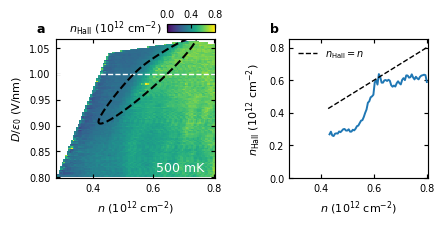

In [4]:
# ---- Hot (500 mK) hall-density map (a) + n_Hall linecut at D = 1 V/nm (b) ----
# Layout/style follows Fermiology-and-the-cCSC ed-fig-AH-hysteresis composites.
from matplotlib.gridspec import GridSpec


def hall_density_500mK_data(ind=2):
    files = [1618, 1619, 1620, 1621]
    ns = np.array([0.45, 0.72, 0.8, 0.8, 0.28])
    Ds = np.array([1.04, 1.065, 1.058, 0.80, 0.80])
    nx, ny = 101, 101
    verts = np.column_stack([ns, Ds])

    zss = []
    for file in files:
        data = sl.pload(file_path, file)
        xs = data['xs'][0]  # top gate
        ys = data['xs'][1]  # back gate
        I = data['sr830_4_X']
        I = np.pad(I, (0, len(xs) - len(I)), 'constant', constant_values=(np.nan, np.nan))
        Vxx = data[f'sr830_{ind}_X']
        Vxx = np.pad(Vxx, (0, len(xs.ravel()) - len(Vxx)), 'constant', constant_values=(np.nan, np.nan))
        zs = Vxx / I
        xs, ys = calculate_n_D(xs, ys, dtg=17.25, dbg=25.5)
        xs, ys, zs = raster.pcolorize_data(zs, verts, nx, ny, 0, rev_x=False, rev_y=True)
        zss.append(zs)

    rxy100 = (zss[1] - zss[2]) / 2  # 100 mT
    rxy200 = (zss[0] - zss[3]) / 2  # 200 mT
    n_hall = -0.1 / (rxy100 - rxy200) / e / 1E16
    return xs, ys, n_hall


# -- Global colorbar geometry (repo convention) --
cb_width = 0.10          # colorbar width in figure fraction
cb_height_inches = 0.08  # colorbar height in inches (fixed across fig sizes)
label_spacer = 0.04

scale = 0.6
fig = plt.figure(figsize=(8.0*scale, 3.0*scale))
cb_height_frac = cb_height_inches / fig.get_size_inches()[1]
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1], wspace=0.5)

xs, ys, n_hall = hall_density_500mK_data()

################ Panel a ##################
ax1 = fig.add_subplot(gs[0, 0])
norm = colors.Normalize(vmin=0, vmax=0.8)
plot = ax1.pcolormesh(xs, ys, n_hall, norm=norm, cmap='viridis', rasterized=True, lw=0)
ax1.set_xlabel(r'$n$ ($10^{12}$ $\mathrm{cm^{-2}}$)')
ax1.set_ylabel(r'$D/\epsilon_0$ (V/nm)')
ax1.axhline(1.0, color='w', ls='--', lw=1)  # panel-b linecut location
ax1.text(0.63, 0.03, '500 mK', color='w', transform=ax1.transAxes, ha='left', va='bottom')

points = np.array([[0.42, 0.92], [0.61, 0.99], [0.74, 1.08], [0.6, 1.04], \
                   [0.52, 1.0], [0.45, 0.93]])
points += [-0.0, -0.01]
csc_patch(fig, ax1, points, color='black')

fig.canvas.draw()
pos = ax1.get_position()
cax = fig.add_axes([pos.x1 - cb_width, pos.y1 + 0.04, cb_width, cb_height_frac])
cb = plt.colorbar(plot, cax=cax, ticks=[0, 0.4, 0.8], orientation='horizontal')
cb.ax.annotate(r'$n_{\mathrm{Hall}}$ ($10^{12}$ $\mathrm{cm^{-2}}$)', xy=(-0.10, 0.5),
               xycoords='axes fraction', ha='right', va='center',
               fontsize=plt.rcParams['axes.labelsize'])
cb.ax.xaxis.set_ticks_position('top')
cb.ax.xaxis.set_label_position('top')
fig.text(pos.x0 - label_spacer, pos.y1 + label_spacer, 'a', fontweight='bold')

################ Panel b ##################
ax2 = fig.add_subplot(gs[0, 1])
i0 = np.argmin(np.abs(ys[:, 0] - 1.0))
n_cut, nh_cut = xs[i0, :], n_hall[i0, :]
mask = np.isfinite(nh_cut)
ax2.plot(n_cut[mask][1:], nh_cut[mask][1:], color='C0')
lims = [n_cut[mask].min(), n_cut[mask].max()]
ax2.plot(lims, lims, color='k', ls='--', lw=1, label=r'$n_{\mathrm{Hall}} = n$')
ax2.set_xlabel(r'$n$ ($10^{12}$ $\mathrm{cm^{-2}}$)')
ax2.set_ylabel(r'$n_{\mathrm{Hall}}$ ($10^{12}$ $\mathrm{cm^{-2}}$)')
ax2.set_xlim(ax1.get_xlim())  # align n axes so features line up across panels
ax2.set_ylim(0, 0.85)
ax2.legend(frameon=False)
pos = ax2.get_position()
fig.text(pos.x0 - label_spacer, pos.y1 + label_spacer, 'b', fontweight='bold')

# ax2.plot(lims, np.array(lims)/4 + 0.41, color='C2')
# ax2.plot(lims, np.array(lims)/4 + 0.18)

save_fig(fig, "halldensity_hot_linecut")